In [1]:
import pandas as pd, numpy as np, glob, os
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
IMG = "../images"
os.makedirs(IMG, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"{IMG}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

C = "../data/cleaned"
df = {}
for f in sorted(glob.glob(os.path.join(C, "*_clean.csv"))):
    name = os.path.basename(f).replace("_clean.csv", "")
    cols = pd.read_csv(f, nrows=0).columns
    df[name] = pd.read_csv(f, parse_dates=[c for c in cols if "date" in c.lower()])
print("Loaded", len(df), "tables")

Loaded 12 tables


In [2]:
mat, wh = df["raw_materials"], df["warehouses"]
po, pol = df["purchase_orders"].copy(), df["purchase_order_lines"]
po["PlannedLeadDays"] = (po["ExpectedDeliveryDate"] - po["OrderDate"]).dt.days

inv = (df["warehouse_inventory"]
       .merge(mat[["MaterialID", "MaterialName"]], on="MaterialID", how="left")
       .merge(wh[["WarehouseID", "WarehouseName"]], on="WarehouseID", how="left"))

mv = (df["stock_movements"]
      .merge(mat[["MaterialID", "MaterialName"]], on="MaterialID", how="left")
      .merge(wh[["WarehouseID", "WarehouseName"]], on="WarehouseID", how="left"))
mv["Month"] = mv["Date"].dt.to_period("M")

sales = df["sales_orders"].copy()
sales["Month"] = sales["OrderDate"].dt.to_period("M")

sh = df["shipment_tracking"]
known = sh[sh["Status"] != "Unknown"].dropna(subset=["ShipDate"]).copy()
known["Month"] = known["ShipDate"].dt.to_period("M")

buy = pol.merge(po[["PO_ID", "OrderDate"]].drop_duplicates("PO_ID"), on="PO_ID")
buy["Month"] = buy["OrderDate"].dt.to_period("M")

# One row per month (Nov 2026 is incomplete, so we stop at Oct 2026)
LAST_FULL = pd.Period("2026-10")
monthly = pd.concat([
    sales.groupby("Month").agg(sales_orders=("SalesOrderID", "nunique"),
                               units_demanded=("Quantity", "sum")),
    buy.groupby("Month").agg(units_purchased=("Quantity", "sum"), spend=("LineTotal", "sum")),
    mv.groupby("Month")["Quantity"].sum().rename("units_received"),
    known.groupby("Month")["Status"].apply(lambda s: (s == "Delayed").mean() * 100).rename("delayed_pct"),
], axis=1)
monthly = monthly[monthly.index <= LAST_FULL]

print(monthly.shape)
monthly.head()

(34, 6)


,sales_orders,units_demanded,units_purchased,spend,units_received,delayed_pct
Month,,,,,,
2024-01,116,11890.0,120179.0,1042973.40,3822.0,30.232558
2024-02,120,12262.0,76633.0,675739.75,10718.0,26.086957
2024-03,141,15094.0,83970.0,674404.05,16134.0,32.558140
2024-04,110,11368.0,74841.0,571083.05,7791.0,19.327731
2024-05,127,13348.0,93727.0,795787.85,22968.0,26.000000


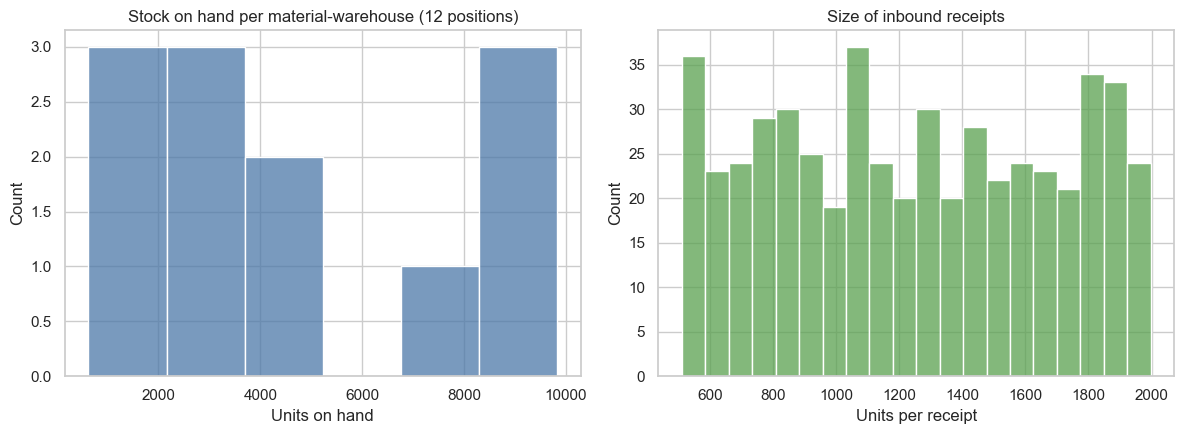

In [3]:
#Chart 1: Inventory distribution histogram

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(inv["QuantityOnHand"], bins=6, ax=ax[0], color="#4C78A8")
ax[0].set(title="Stock on hand per material-warehouse (12 positions)", xlabel="Units on hand")
sns.histplot(mv["Quantity"], bins=20, ax=ax[1], color="#59A14F")
ax[1].set(title="Size of inbound receipts", xlabel="Units per receipt")
save("01_inventory_histogram")

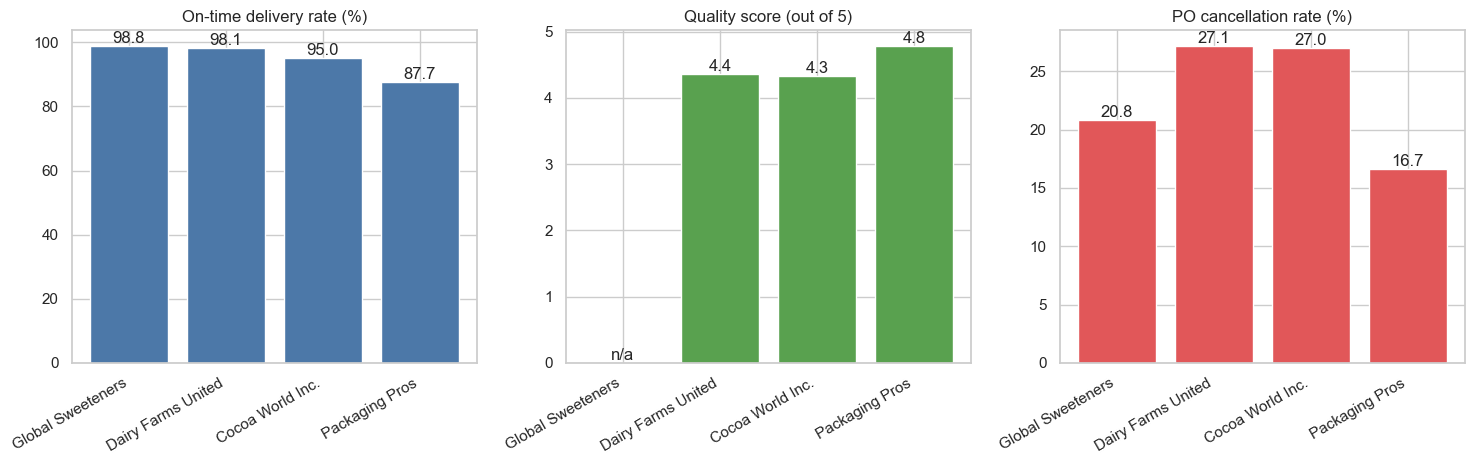

In [4]:
#Chart 2: Supplier performance bar chart

sup = df["suppliers"].merge(df["supplier_performance"].drop(columns="SupplierName"), on="SupplierID")
st = pd.crosstab(po["SupplierID"], po["Status"])
sup["CancelRate"] = sup["SupplierID"].map(st["Cancelled"] / st.sum(axis=1) * 100)
sup["OnTime"] = sup["OnTimeDeliveryRate"] * 100
sup = sup.sort_values("OnTime", ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
panels = [(ax[0], "OnTime", "On-time delivery rate (%)", "#4C78A8"),
          (ax[1], "QualityScore", "Quality score (out of 5)", "#59A14F"),
          (ax[2], "CancelRate", "PO cancellation rate (%)", "#E15759")]
for a, col, title, color in panels:
    bars = a.bar(sup["SupplierName"], sup[col].fillna(0), color=color)
    a.set_title(title)
    plt.setp(a.get_xticklabels(), rotation=30, ha="right")
    for b, v in zip(bars, sup[col]):
        a.text(b.get_x() + b.get_width() / 2, b.get_height(),
               "n/a" if pd.isna(v) else f"{v:.1f}", ha="center", va="bottom")
save("02_supplier_performance")

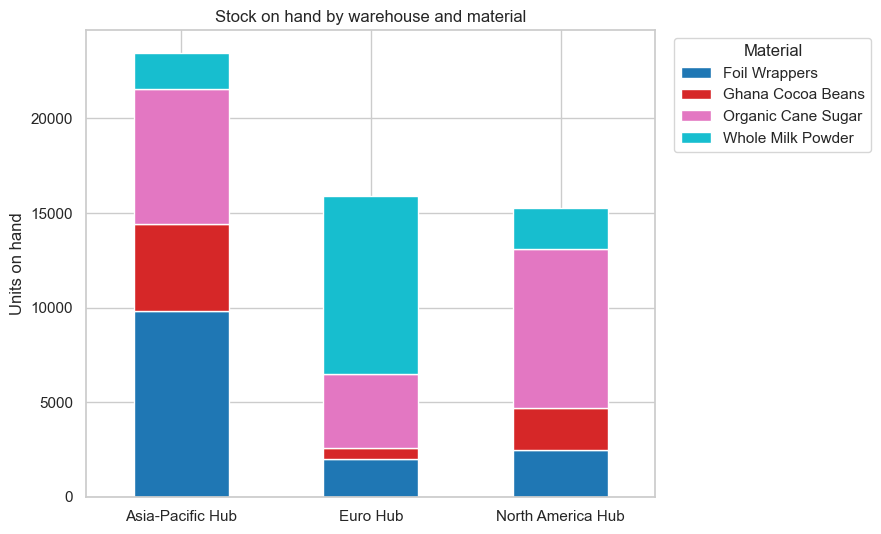

In [5]:
#Chart 3: Warehouse stock chart

(inv.pivot_table(index="WarehouseName", columns="MaterialName",
                 values="QuantityOnHand", aggfunc="sum")
    .plot(kind="bar", stacked=True, figsize=(9, 5.5), colormap="tab10"))
plt.title("Stock on hand by warehouse and material")
plt.ylabel("Units on hand")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(title="Material", bbox_to_anchor=(1.02, 1), loc="upper left")
save("03_warehouse_stock")

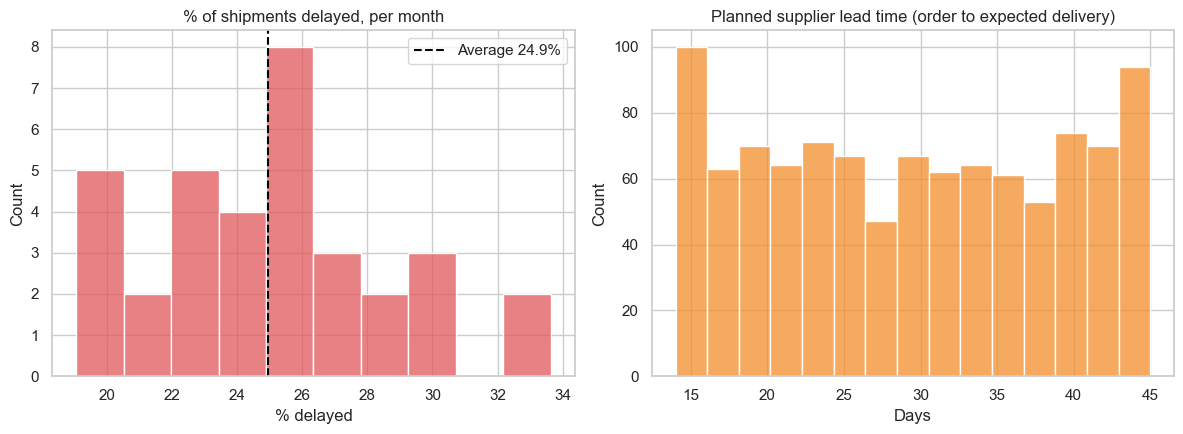

In [7]:
#Chart 4: Shipping delay histogram

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(monthly["delayed_pct"].dropna(), bins=10, ax=ax[0], color="#E15759")
ax[0].axvline(monthly["delayed_pct"].mean(), color="black", linestyle="--",
              label=f"Average {monthly['delayed_pct'].mean():.1f}%")
ax[0].set(title="% of shipments delayed, per month", xlabel="% delayed")
ax[0].legend()
sns.histplot(po["PlannedLeadDays"].dropna(), bins=15, ax=ax[1], color="#F28E2B")
ax[1].set(title="Planned supplier lead time (order to expected delivery)", xlabel="Days")
save("04_shipping_delay_histogram")

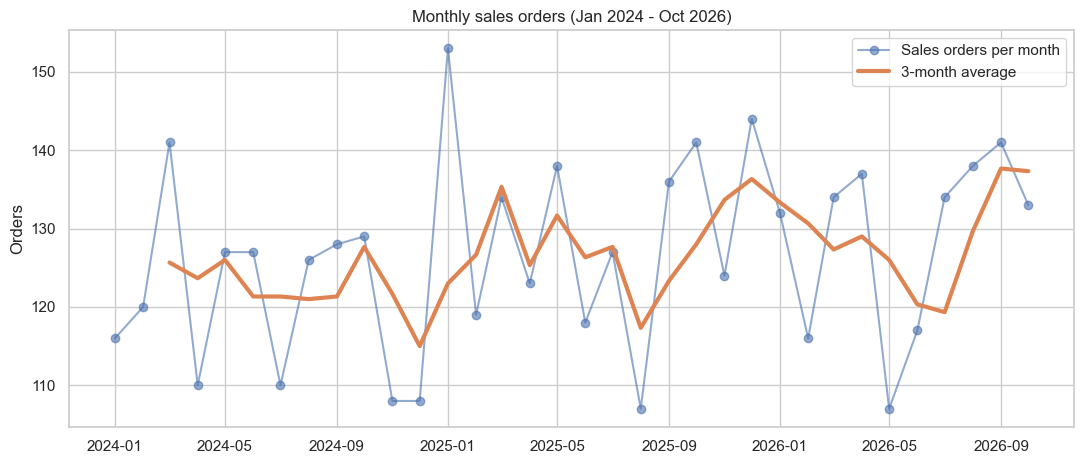

In [8]:
#Chart 5: Monthly orders line chart

m = monthly.copy()
m.index = m.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(m.index, m["sales_orders"], marker="o", alpha=0.6, label="Sales orders per month")
ax.plot(m.index, m["sales_orders"].rolling(3).mean(), linewidth=3, label="3-month average")
ax.set(title="Monthly sales orders (Jan 2024 - Oct 2026)", ylabel="Orders")
ax.legend()
save("05_monthly_orders")

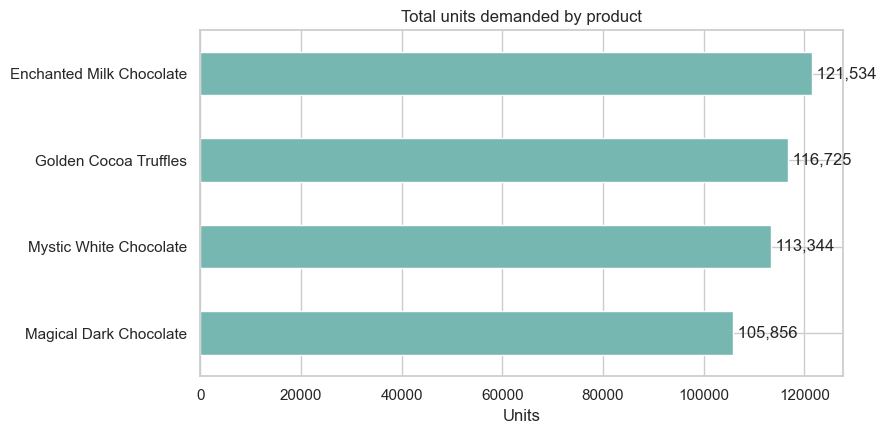

In [9]:
#Chart 6: Product demand bar chart

dem = sales.groupby("ProductName")["Quantity"].sum().sort_values()
ax = dem.plot(kind="barh", color="#76B7B2", figsize=(9, 4.5))
for i, v in enumerate(dem):
    ax.text(v, i, f" {v:,.0f}", va="center")
ax.set(title="Total units demanded by product", xlabel="Units", ylabel="")
save("06_product_demand")

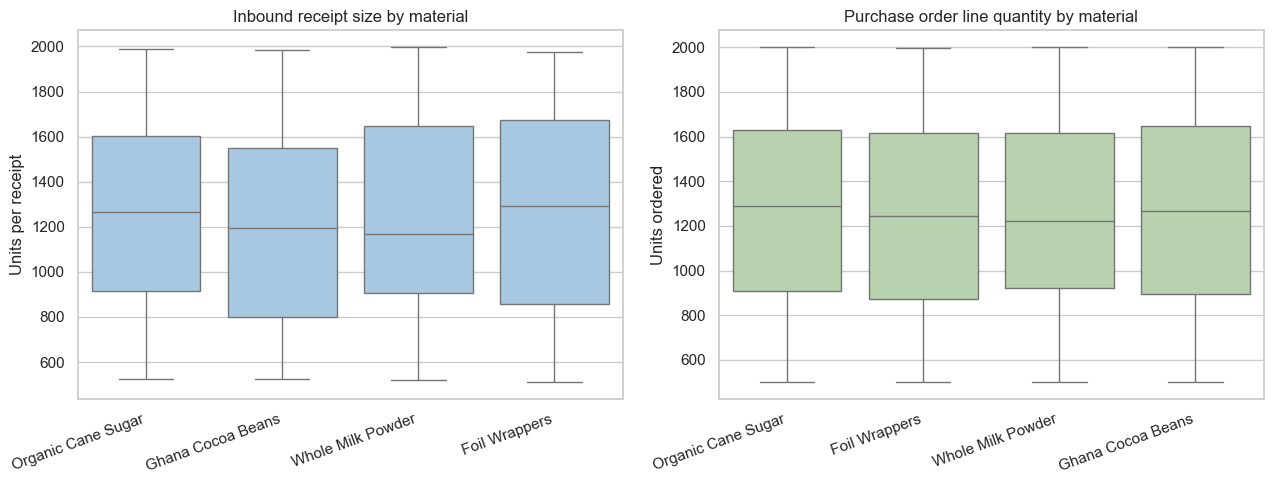

In [10]:
#Chart 7: Inventory box plot

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=mv, x="MaterialName", y="Quantity", ax=ax[0], color="#9ECAE9")
ax[0].set(title="Inbound receipt size by material", xlabel="", ylabel="Units per receipt")
pl = pol.merge(mat[["MaterialID", "MaterialName"]], on="MaterialID", how="left")
sns.boxplot(data=pl, x="MaterialName", y="Quantity", ax=ax[1], color="#B6D7A8")
ax[1].set(title="Purchase order line quantity by material", xlabel="", ylabel="Units ordered")
for a in ax:
    plt.setp(a.get_xticklabels(), rotation=20, ha="right")
save("07_inventory_boxplot")

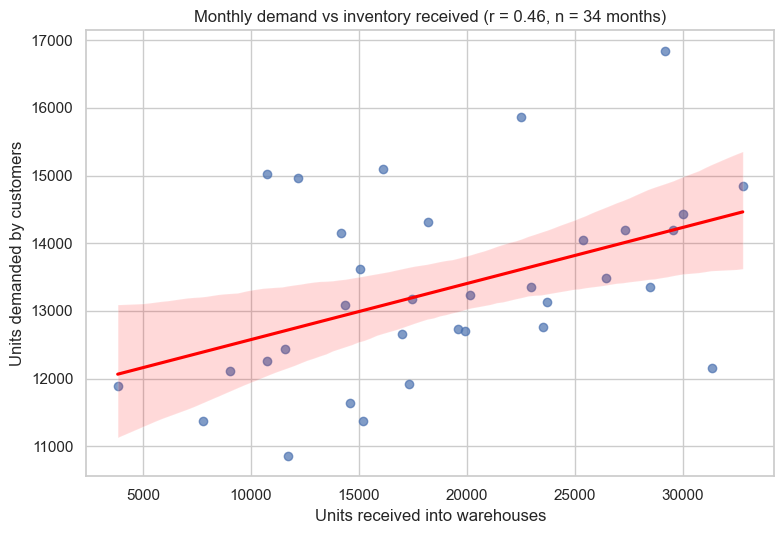

In [11]:
#Chart 8: Scatter plot (demand vs inventory received)

s = monthly.dropna(subset=["units_demanded", "units_received"])
r = s["units_demanded"].corr(s["units_received"])
plt.figure(figsize=(8, 5.5))
sns.regplot(data=s, x="units_received", y="units_demanded",
            scatter_kws={"alpha": 0.7}, line_kws={"color": "red"})
plt.title(f"Monthly demand vs inventory received (r = {r:.2f}, n = {len(s)} months)")
plt.xlabel("Units received into warehouses")
plt.ylabel("Units demanded by customers")
save("08_demand_vs_inventory")

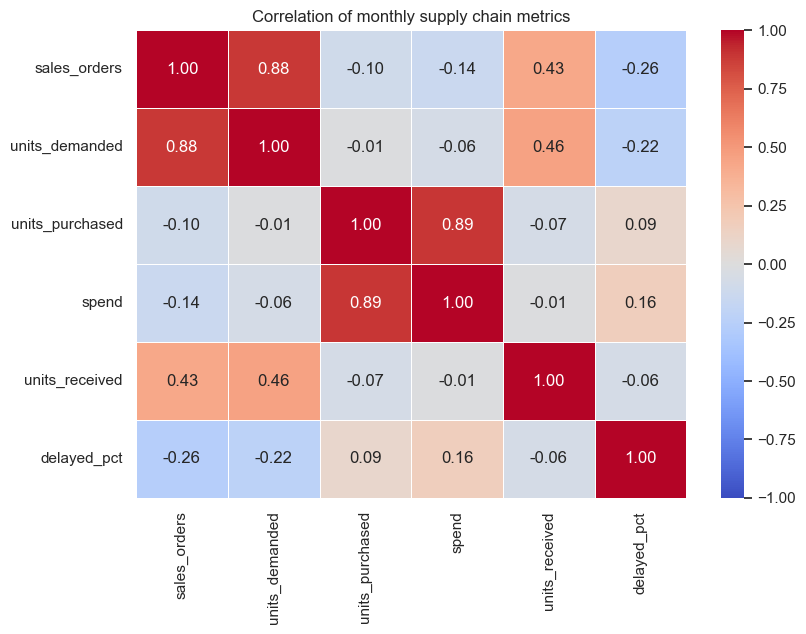

In [12]:
#Chart 9: Correlation heatmap

cols = ["sales_orders", "units_demanded", "units_purchased", "spend", "units_received", "delayed_pct"]
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(monthly[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation of monthly supply chain metrics")
save("09_correlation_heatmap")

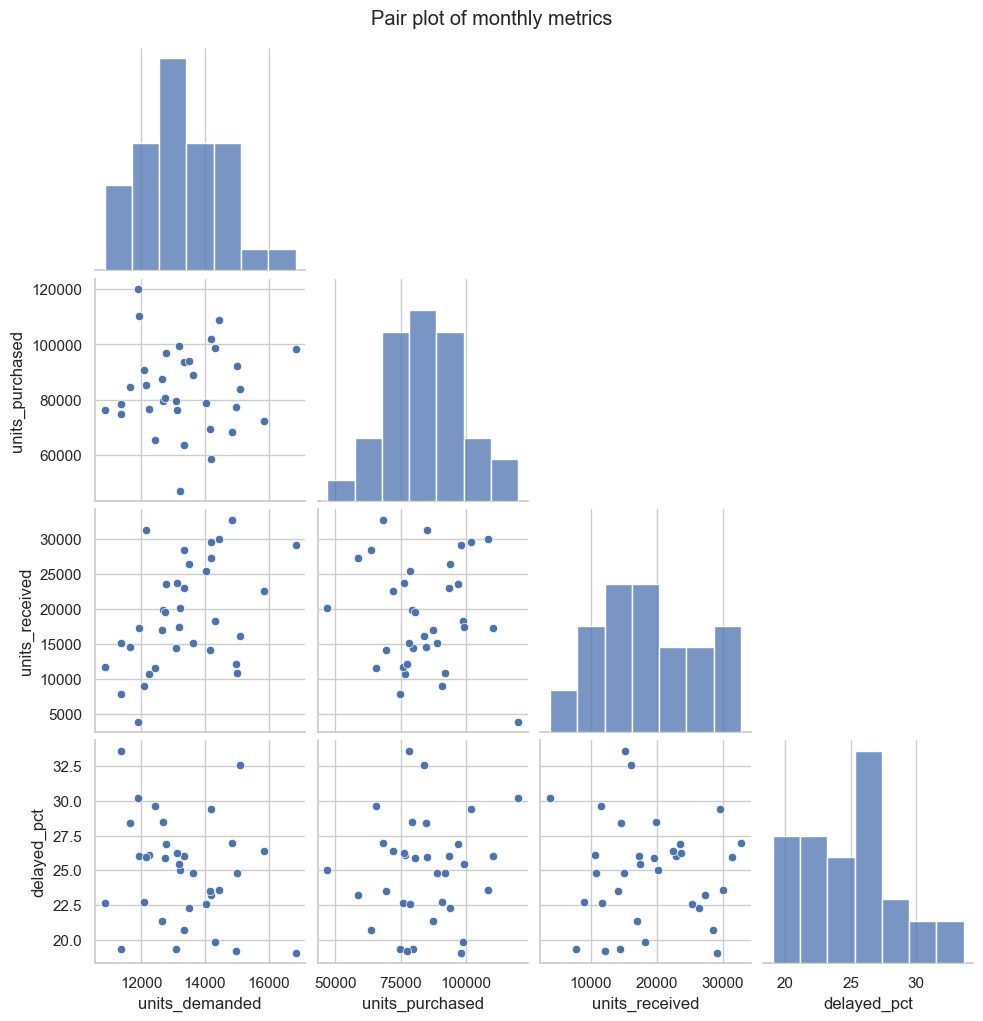

In [13]:
#Chart 10: Pair plot

g = sns.pairplot(monthly[["units_demanded", "units_purchased", "units_received", "delayed_pct"]].dropna(),
                 diag_kind="hist", corner=True)
g.fig.suptitle("Pair plot of monthly metrics", y=1.02)
g.savefig(f"{IMG}/10_pair_plot.png", dpi=150, bbox_inches="tight")
plt.show()